In [1]:
from pathlib import Path
import numpy as np,pandas as pd, matplotlib.pyplot as plt,seaborn as sns

In [2]:
DATA =Path("../NewYorkStock")

In [3]:
prices= pd.read_csv(DATA/"prices-split-adjusted.csv",parse_dates=["date"])

In [4]:
secs =pd.read_csv(DATA /"securities.csv")

In [5]:
display(prices.head()); prices.info(); display(prices.describe())

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


<class 'pandas.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[us]
 1   symbol  851264 non-null  str           
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[us](1), float64(5), str(1)
memory usage: 45.5 MB


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294038,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


In [6]:
print(prices.isna().sum()) #counts missing values per col

date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64


In [7]:
print(prices.symbol.nunique(), "symbols,from", prices.date.min(), "to",prices.date.max())


501 symbols,from 2010-01-04 00:00:00 to 2016-12-30 00:00:00


In [8]:
print(secs.columns.tolist())

['Ticker symbol', 'Security', 'SEC filings', 'GICS Sector', 'GICS Sub Industry', 'Address of Headquarters', 'Date first added', 'CIK']


In [9]:
print("zero-volume rows:", (prices.volume == 0).sum())

zero-volume rows: 21


In [10]:
tickers = ["PYPL", "NVDA", "MSFT", "AMZN", "GOOGL"]
print("missing from data:", [t for t in tickers if t not in prices.symbol.unique()])


missing from data: []


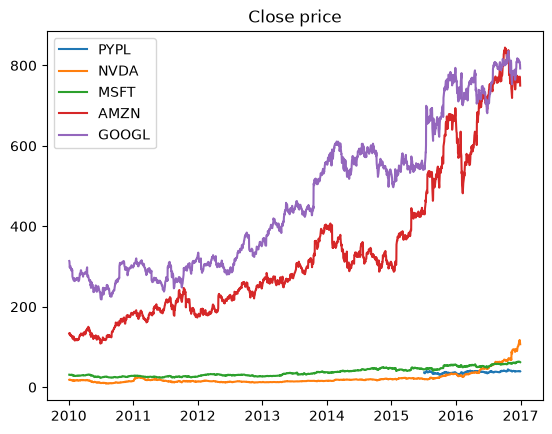

In [12]:
for s in tickers:
    d=prices[prices.symbol ==s]
    plt.plot(d.date,d.close,label=s)
plt.title("Close price")
plt.legend()
plt.savefig("figures/close_pricee.png", dpi=150, bbox_inches="tight")
plt.show()

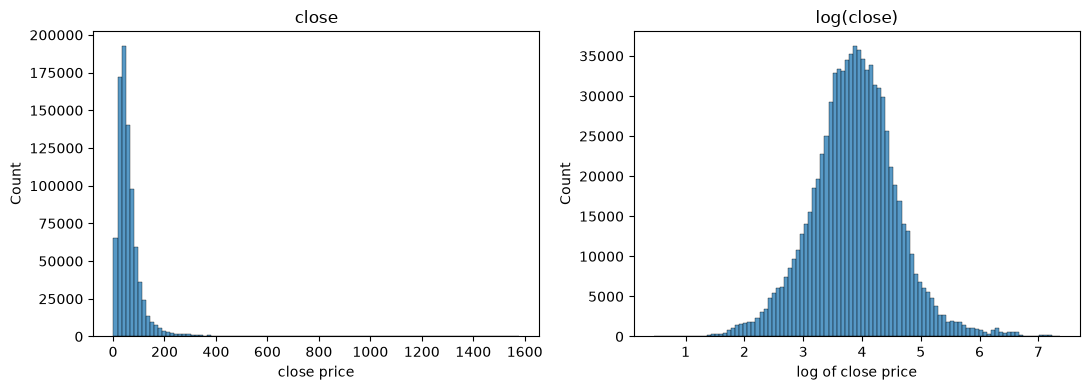

In [16]:
fig,ax = plt.subplots(1,2,figsize=(11,4))
sns.histplot(prices.close, bins=100, ax=ax[0])
ax[0].set(title="close", xlabel="close price")
sns.histplot(np.log(prices.close), bins=100, ax = ax[1])
ax[1].set(title="log(close)",xlabel="log of close price")
plt.tight_layout()
plt.savefig("figures/close_dist.png",dpi=150, bbox_inches="tight")
plt.show()

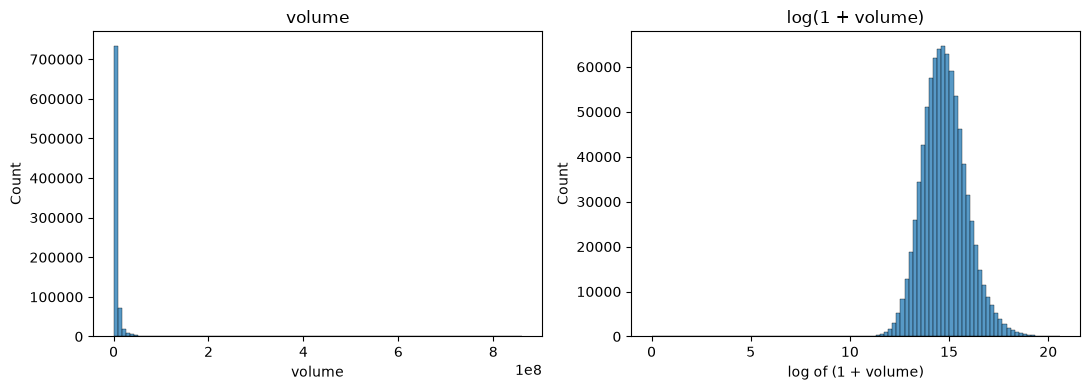

In [17]:
# distribution of the volume (raw and log)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(prices.volume, bins=100, ax=ax[0])
ax[0].set(title="volume", xlabel="volume")
sns.histplot(np.log1p(prices.volume), bins=100, ax=ax[1])
ax[1].set(title="log(1 + volume)", xlabel="log of (1 + volume)")
plt.tight_layout()
plt.savefig("figures/volume_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# daily return of each company
prices = prices.sort_values(["symbol", "date"])
prices["ret_1"] = prices.groupby("symbol")["close"].pct_change() #computes (today − yesterday) / yesterday
print(prices["ret_1"].describe())

count    850763.000000
mean          0.000592
std           0.018127
min          -0.618934
25%          -0.007821
50%           0.000570
75%           0.009051
max           2.096103
Name: ret_1, dtype: float64


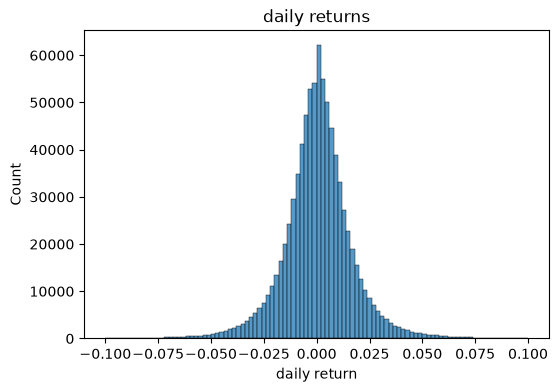

In [21]:
# distribution of the daily returns
plt.figure(figsize=(6, 4))
sns.histplot(prices["ret_1"].dropna(), bins=100, binrange=(-0.1, 0.1))
plt.title("daily returns")
plt.xlabel("daily return")
plt.savefig("figures/returns_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
print("duplicate (date, symbol):", prices.duplicated(["date", "symbol"]).sum())

duplicate (date, symbol): 0


In [23]:
print("high below open/close:", (prices.high < prices[["open", "close"]].max(axis=1)).sum())
print("low above open/close:", (prices.low > prices[["open", "close"]].min(axis=1)).sum())

high below open/close: 0
low above open/close: 0


In [24]:
n_days = prices.groupby("symbol").size()
print(n_days.describe())

count     501.000000
mean     1699.129741
std       253.731238
min       126.000000
25%      1762.000000
50%      1762.000000
75%      1762.000000
max      1762.000000
dtype: float64


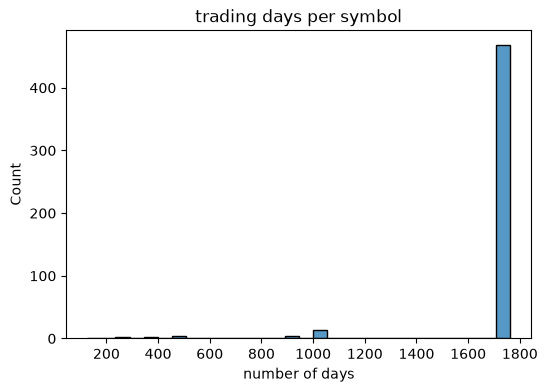

In [25]:
plt.figure(figsize=(6, 4))
sns.histplot(n_days, bins=30)
plt.title("trading days per symbol")
plt.xlabel("number of days")
plt.savefig("figures/days_per_symbol.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
prices["target"] = prices.groupby("symbol")["close"].shift(-1)

In [29]:
# features
prices["ret_5"] = prices.groupby("symbol")["close"].pct_change(5)
prices["range"] = (prices["high"] - prices["low"]) / prices["close"]
prices["ma5_ratio"] = prices.groupby("symbol")["close"].transform(lambda s: s.rolling(5).mean()) / prices["close"]
prices["log_vol"] = np.log1p(prices["volume"])

In [31]:
print(prices.shape)
prices = prices.dropna()
print(prices.shape)
print(prices[["symbol", "date", "close", "target"]].head())

(848258, 13)
(848258, 13)
     symbol       date      close     target
2590      A 2010-01-11  22.045780  21.781117
3058      A 2010-01-12  21.781117  21.952789
3526      A 2010-01-13  21.952789  22.281832
3994      A 2010-01-14  22.281832  21.766810
4462      A 2010-01-15  21.766810  22.031474


In [32]:
from sklearn.preprocessing import StandardScaler

In [33]:
feats = ["open", "high", "low", "close", "log_vol", "ret_1", "ret_5", "range", "ma5_ratio"]

In [34]:
prices = prices.sort_values("date")
cut = prices["date"].iloc[int(0.8 * len(prices))]
train = prices[prices["date"] <= cut]
test = prices[prices["date"] > cut]
print("cut date:", cut, "| train:", len(train), "| test:", len(test))

cut date: 2015-08-26 00:00:00 | train: 678834 | test: 169424


In [36]:
X_train, y_train = train[feats].values, train[["target"]].values
X_test, y_test = test[feats].values, test[["target"]].values

In [37]:
# standardize (fit on the training set only)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [38]:
sc_y = StandardScaler()
y_train = sc_y.fit_transform(y_train)
y_test = sc_y.transform(y_test)

In [39]:
print(X_train.mean(axis=0).round(2))
print(X_test.mean(axis=0).round(2))

[-0.  0. -0.  0.  0. -0. -0.  0. -0.]
[ 0.37  0.37  0.36  0.37 -0.05 -0.   -0.01  0.09  0.01]
